In [207]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
path = r"E:\Datasets\Covid19"

# Read the dataset

In [2]:
country_wise_latest = pd.read_csv(f"{path}\\country_wise_latest.csv")
covid_19_clean_complete = pd.read_csv(f"{path}\\covid_19_clean_complete.csv")
day_wise = pd.read_csv(f"{path}\\day_wise.csv")
full_grouped = pd.read_csv(f"{path}\\full_grouped.csv")
usa_county_wise = pd.read_csv(f"{path}\\usa_county_wise.csv")
worldometer_data = pd.read_csv(f"{path}\\worldometer_data.csv")

In [3]:
full_grouped.shape

(35156, 10)

In [4]:
full_grouped.columns

Index(['Date', 'Country/Region', 'Confirmed', 'Deaths', 'Recovered', 'Active',
       'New cases', 'New deaths', 'New recovered', 'WHO Region'],
      dtype='str')

# Understand The Dataset

## full_grouped

The dataset is country wise 
- Date -> The date on which the data was recorded.
- Country/Region -> The country or region where the cases were reported.
- Confirmed -> The cumulative number of confirmed COVID-19 cases reported up to that date.
- Deaths -> The cumulative number of deaths attributed to COVID-19 up to that date.
- Recovered -> The cumulative number of recovered cases up to that date.
- Active -> The number of currently active cases on that date.
- New cases -> The number of newly confirmed COVID-19 cases reported on that date.
- New deaths -> The number of newly reported COVID-19 deaths on that date.
- New recovered -> The number of newly reported recovered cases on that date.
- WHO Region -> The World Health Organizatio (WHO) region to which the country belongs.

Note: The cumulative number means that it includes all cases reported up to and including that date.

In [5]:
full_grouped

,Date,Country/Region,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,WHO Region
0,2020-01-22,Afghanistan,0,0,0,0,0,0,0,Eastern Mediterranean
1,2020-01-22,Albania,0,0,0,0,0,0,0,Europe
2,2020-01-22,Algeria,0,0,0,0,0,0,0,Africa
3,2020-01-22,Andorra,0,0,0,0,0,0,0,Europe
4,2020-01-22,Angola,0,0,0,0,0,0,0,Africa
...,...,...,...,...,...,...,...,...,...,...
35151,2020-07-27,West Bank and Gaza,10621,78,3752,6791,152,2,0,Eastern Mediterranean
35152,2020-07-27,Western Sahara,10,1,8,1,0,0,0,Africa
35153,2020-07-27,Yemen,1691,483,833,375,10,4,36,Eastern Mediterranean
35154,2020-07-27,Zambia,4552,140,2815,1597,71,1,465,Africa


# Part 1: 
Tasks:
1. Display the first 5 rows of the dataset.
2. Display the dataset shape (number of rows and columns).
3. Show information about columns and data types.
4. Calculate basic statistical summaries for numerical columns.

Questions:
- What does each row represent?
- What are the main features available in the dataset?
- Which columns are numerical and which are categorical?


In [6]:
full_grouped.head()

,Date,Country/Region,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,WHO Region
0,2020-01-22,Afghanistan,0,0,0,0,0,0,0,Eastern Mediterranean
1,2020-01-22,Albania,0,0,0,0,0,0,0,Europe
2,2020-01-22,Algeria,0,0,0,0,0,0,0,Africa
3,2020-01-22,Andorra,0,0,0,0,0,0,0,Europe
4,2020-01-22,Angola,0,0,0,0,0,0,0,Africa


In [7]:
full_grouped.shape

(35156, 10)

In [8]:
full_grouped.columns

Index(['Date', 'Country/Region', 'Confirmed', 'Deaths', 'Recovered', 'Active',
       'New cases', 'New deaths', 'New recovered', 'WHO Region'],
      dtype='str')

In [9]:
full_grouped.dtypes

Date                str
Country/Region      str
Confirmed         int64
Deaths            int64
Recovered         int64
Active            int64
New cases         int64
New deaths        int64
New recovered     int64
WHO Region          str
dtype: object

In [10]:
full_grouped.describe()

,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered
count,3.515600e+04,35156.000000,3.515600e+04,3.515600e+04,35156.00000,35156.000000,35156.000000
mean,2.356663e+04,1234.068239,1.104813e+04,1.128443e+04,469.36375,18.603339,269.315593
std,1.499818e+05,7437.238354,6.454640e+04,8.997149e+04,3005.86754,115.706351,2068.063852
min,0.000000e+00,0.000000,0.000000e+00,-2.000000e+00,0.00000,-1918.000000,-16298.000000
25%,1.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.00000,0.000000,0.000000
50%,2.500000e+02,4.000000,3.300000e+01,8.500000e+01,2.00000,0.000000,0.000000
75%,3.640250e+03,78.250000,1.286250e+03,1.454000e+03,75.00000,1.000000,20.000000
max,4.290259e+06,148011.000000,1.846641e+06,2.816444e+06,77255.00000,3887.000000,140050.000000


In [11]:
print("""
Each row represents the report for the \033[1mcomutative and new\033[0m different Covid19 cases up to / on a specific day
""")


Each row represents the report for the comutative and new different Covid19 cases up to / on a specific day



In [12]:
print("""
The main features include
- Date
- Country/Region
- Confirmed
- Deaths
- Recovered
- Active
- New cases
- New deaths
- New recovered
- WHO Region
""")


The main features include
- Date
- Country/Region
- Confirmed
- Deaths
- Recovered
- Active
- New cases
- New deaths
- New recovered
- WHO Region



In [13]:
numerical_features = full_grouped.select_dtypes(include='int64').columns
categorical_features = full_grouped.select_dtypes(include='str').columns
print(f"""
Numerical features:
{numerical_features}
Categorical features:
{categorical_features}
""")


Numerical features:
Index(['Confirmed', 'Deaths', 'Recovered', 'Active', 'New cases', 'New deaths',
       'New recovered'],
      dtype='str')
Categorical features:
Index(['Date', 'Country/Region', 'WHO Region'], dtype='str')



# Part 2
Tasks:
1. Identify missing values.
2. Calculate the percentage of missing values in each column.
3. Check for duplicated records.
4. Check whether date columns are stored correctly.
5. Handle missing or incorrect values appropriately.

Questions:
- Which columns require cleaning?
- Which cleaning approach did you choose and why?


In [14]:
full_grouped.isna().sum()

Date              0
Country/Region    0
Confirmed         0
Deaths            0
Recovered         0
Active            0
New cases         0
New deaths        0
New recovered     0
WHO Region        0
dtype: int64

In [15]:
full_grouped.duplicated().sum()

np.int64(0)

In [16]:
print(full_grouped.dtypes)
full_grouped['Date'] = pd.to_datetime(full_grouped['Date'].str.strip())
print(full_grouped.dtypes)

Date                str
Country/Region      str
Confirmed         int64
Deaths            int64
Recovered         int64
Active            int64
New cases         int64
New deaths        int64
New recovered     int64
WHO Region          str
dtype: object
Date              datetime64[us]
Country/Region               str
Confirmed                  int64
Deaths                     int64
Recovered                  int64
Active                     int64
New cases                  int64
New deaths                 int64
New recovered              int64
WHO Region                   str
dtype: object


In [17]:
print("""
We only needed to convert the data type of Date column from \033[1mstr into datetime\033[0m and we used \033[1mto_datetime()\033[0m
""")


We only needed to convert the data type of Date column from str into datetime and we used to_datetime()



# Part 3: Exploratory Data Analysis

Question 1: Global COVID-19 Overview

1. What is the total number of confirmed cases?
2. What is the total number of deaths?
3. What is the total number of recovered cases?
4. Calculate the death rate and recovery rate.

Question 2: Country Comparison

1. Find the top 10 countries with the highest confirmed cases.
2. Find the top 10 countries with the highest deaths.
3. Compare countries based on recovery rate.

Visualization: Bar charts comparing countries.

Question 3: Time Trend Analysis

1. How did confirmed cases change over time?
2. When were the largest increases observed?
3. How did deaths change compared with cases?

Visualization: Line charts showing trends over time.

Question 4: Spread Analysis
1. Which countries experienced the fastest growth?
2. Which countries controlled the spread better?
3. Are countries with more cases always having more deaths?


In [18]:
final_date = full_grouped['Date'].max()
total_confirm = full_grouped[full_grouped['Date'] == final_date]['Confirmed'].sum()
total_confirm

np.int64(16480485)

In [19]:
total_death = full_grouped[full_grouped['Date'] == final_date]['Deaths'].sum()
total_death

np.int64(654036)

In [20]:
total_recover = full_grouped[full_grouped['Date'] == final_date]['Recovered'].sum()
total_recover

np.int64(9468087)

In [21]:
rate_death = total_death/total_confirm * 100
rate_death

np.float64(3.968548255709708)

In [22]:
rate_recover = total_recover/total_confirm * 100
rate_recover

np.float64(57.450293483474546)

In [23]:
total_active = full_grouped[full_grouped['Date'] == final_date]['Active'].sum()
total_active

np.int64(6358362)

In [24]:
rate_active = total_active/total_confirm * 100
rate_active

np.float64(38.58115826081575)

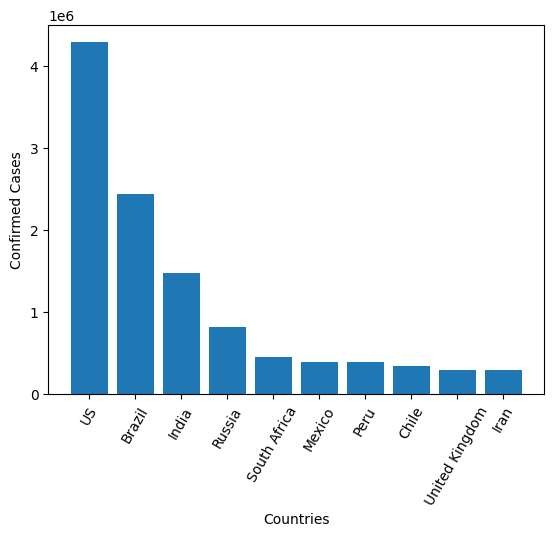

In [25]:
all_countries = full_grouped[full_grouped['Date'] == final_date]
all_countries = all_countries.set_index('Country/Region')
top10_countries_confirmed = all_countries['Confirmed'].nlargest(10)
plt.bar(top10_countries_confirmed.index, top10_countries_confirmed.values)
plt.xlabel('Countries')
plt.ylabel('Confirmed Cases')
plt.xticks(rotation = 60)
plt.show()

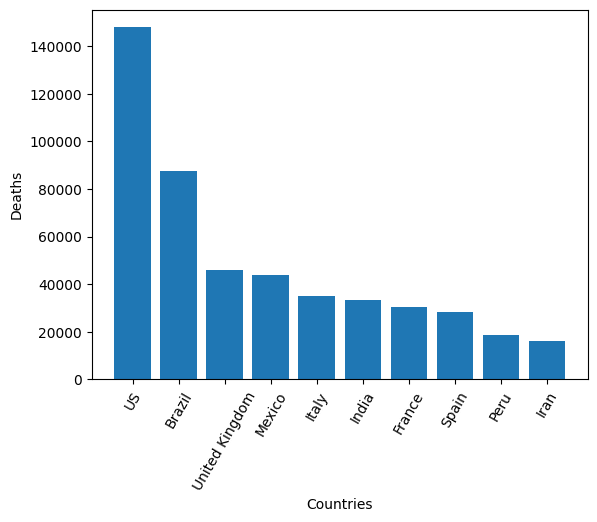

In [26]:
top10_countries_death = all_countries['Deaths'].nlargest(10)
top10_countries_death
plt.bar(top10_countries_death.index, top10_countries_death.values)
plt.xlabel('Countries')
plt.ylabel('Deaths')
plt.xticks(rotation = 60)
plt.show()

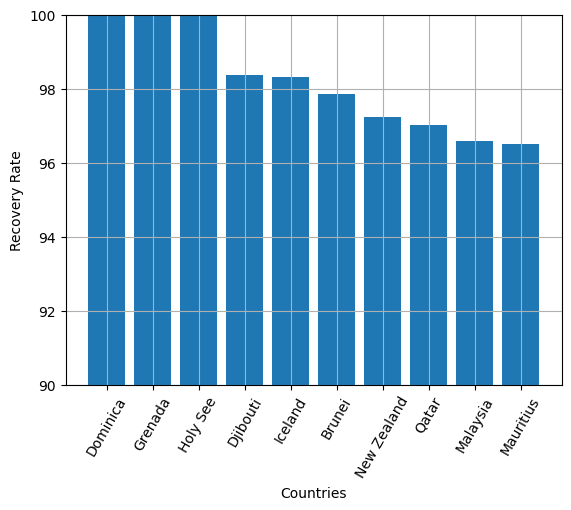

In [29]:
recovery_rate_counteries = all_countries['Recovered']/all_countries['Confirmed'] * 100
top10_recovery_rate_counteries = recovery_rate_counteries.nlargest(10)
plt.bar(top10_recovery_rate_counteries.index, top10_recovery_rate_counteries.values)
plt.xlabel('Countries')
plt.ylabel('Recovery Rate')
plt.xticks(rotation = 60)
plt.ylim(90, 100)
plt.grid()
plt.show()

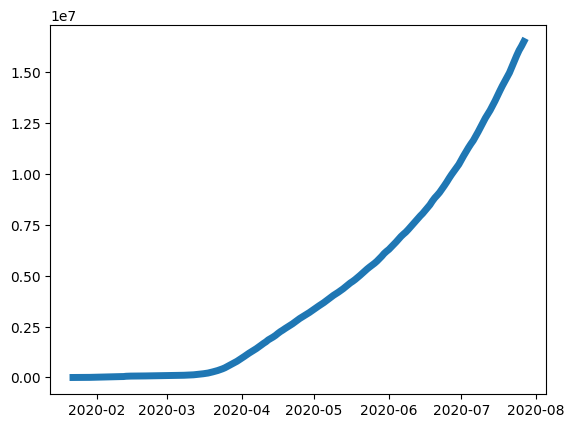

In [81]:
OverTime_confirmed = full_grouped.groupby('Date')['Confirmed'].sum()
plt.plot(OverTime_confirmed.index, OverTime_confirmed, linewidth = 5)
plt.show()

In [47]:
print("the largest increases were in the \033[1mlatest date\033[0m")

the largest increases were in the latest date


0.03968578750031099


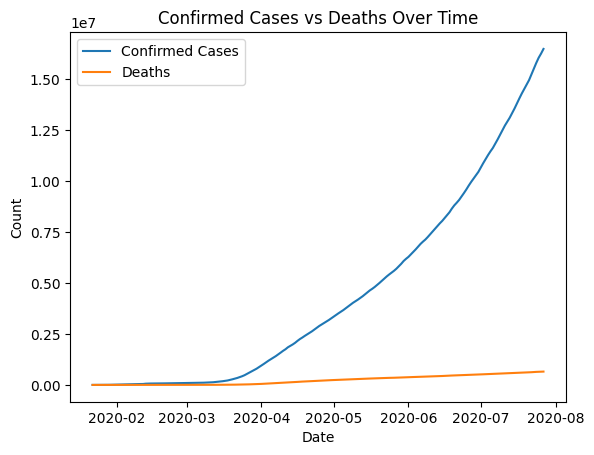

In [141]:
#How did deaths change compared with cases?
cases_changes = full_grouped.groupby('Date')['Confirmed'].sum()
deaths_changes = full_grouped.groupby('Date')['Deaths'].sum()
deaths_compared_cases = (deaths_changes.iloc[-1] -  deaths_changes.iloc[0])/(cases_changes.iloc[-1] - cases_changes.iloc[0])
print(deaths_compared_cases)
plt.plot(cases_changes.index, cases_changes, label='Confirmed Cases')
plt.plot(deaths_changes.index, deaths_changes, label='Deaths')
plt.xlabel('Date')
plt.ylabel('Count')
plt.title('Confirmed Cases vs Deaths Over Time')
plt.legend()
plt.show()

In [169]:
countries_cases = full_grouped.groupby('Country/Region')['Confirmed']
countries_new_cases = full_grouped.groupby('Country/Region')['Confirmed']
growth = countries_cases.last() - countries_cases.first()
top10_counties_growth = growth.nlargest(10)
countries_new_cases = full_grouped.groupby('Country/Region')['New cases']
avg_new_cases = countries_new_cases.mean()
best_controlled = avg_new_cases.nsmallest(10)
print(f"""
the countries that experienced the fastest growth:
{top10_counties_growth}
the countries that controlled the spread better:
{best_controlled}
""")


the countries that experienced the fastest growth:
Country/Region
US                4290258
Brazil            2442375
India             1480073
Russia             816680
South Africa       452529
Mexico             395489
Peru               389717
Chile              347923
United Kingdom     301708
Iran               293606
Name: Confirmed, dtype: int64
the countries that controlled the spread better:
Country/Region
Western Sahara           0.053191
Holy See                 0.063830
Greenland                0.074468
Saint Kitts and Nevis    0.090426
Dominica                 0.095745
Laos                     0.106383
Grenada                  0.122340
Saint Lucia              0.127660
Timor-Leste              0.127660
Fiji                     0.143617
Name: New cases, dtype: float64



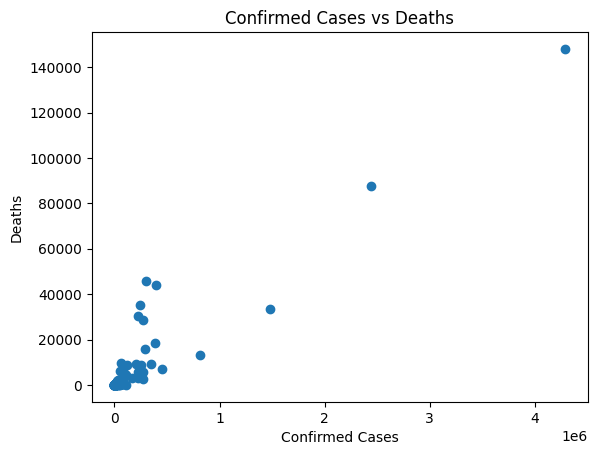

Are countries with more cases always having more deaths? No, not always (the correlation = 0.9120159504553668)


In [190]:
countries_cases = full_grouped.groupby('Country/Region')[['Confirmed','Deaths', 'Recovered']].last()
countries_with_top10_confirmed = countries_cases.sort_values(ascending=False, by='Confirmed').head(10)
plt.scatter(
    countries_cases['Confirmed'],
    countries_cases['Deaths']
)
plt.xlabel('Confirmed Cases')
plt.ylabel('Deaths')
plt.title('Confirmed Cases vs Deaths')
plt.show()
confirmed_deaths_corr = full_grouped['Confirmed'].corr(full_grouped['Deaths'])
print(f"Are countries with more cases always having more deaths? No, not always (the correlation = {confirmed_deaths_corr})")

## Part 5: Advanced Analysis Challenges ⭐
Challenge 1: Create a COVID Impact Score

1. Create your own metric that combines:
    - Confirmed cases
    - Deaths
    - Recovery rate

2. Rank countries according to this score.

Challenge 2: Country Classification

1. Divide countries into groups:
- Low impact
- Medium impact
- High impact

2. Define your criteria and explain your decision.

Challenge 3: Find Interesting Patterns

Find examples of:
- Countries with many cases but low death rate.
- Countries with fewer cases but high death rate.
- Unusual trends over time.

In [256]:
Recovery_rate = countries_cases['Recovered']/countries_cases['Confirmed'] * 100
Deaths_rate = countries_cases['Deaths']/countries_cases['Confirmed'] * 100
impactScore = Deaths_rate - Recovery_rate
normalize = MinMaxScaler()
impactScore = impactScore.to_frame() 
impactScore_scaled = normalize.fit_transform(impactScore)
impactScore_scaled = pd.DataFrame(data = impactScore_scaled, columns=['impactScore'], index=impactScore.index)
impactScore_scaled['impactScore'] = impactScore_scaled['impactScore'] * 100
def ImpactScore(country:str):
    target_country = impactScore_scaled.loc[country]
    return target_country
ImpactScore('Egypt')

impactScore    58.717743
Name: Egypt, dtype: float64

In [261]:
ranking = impactScore_scaled.sort_values(by="impactScore", ascending=False)
ranking

,impactScore
Country/Region,
United Kingdom,100.000000
Netherlands,96.914527
Canada,93.864537
Sweden,93.428052
Syria,92.343157
...,...
Djibouti,2.412291
Iceland,1.927705
Dominica,0.000000


In [283]:
impacting = ranking
bins = [0, 40, 70, 100]
labels = ['low', 'medium', 'high']
impacting['impact_degree'] = pd.cut(impacting['impactScore'], bins=bins, labels=labels)
impacting

,impactScore,impact_degree
Country/Region,,
United Kingdom,100.000000,high
Netherlands,96.914527,high
Canada,93.864537,high
Sweden,93.428052,high
Syria,92.343157,high
...,...,...
Djibouti,2.412291,low
Iceland,1.927705,low
Dominica,0.000000,NaN


In [284]:
print("""
I divided the COVID Impact Score into three categories based on its normalized 0–100 scale. Countries
with scores below 40 are considered low impact, scores from 40 to below 70 are considered medium 
impact, and scores of 70 or above are considered high impact. I chose these thresholds to provide a 
simple and clear classification where higher scores indicate a greater COVID-19 impact according to 
the defined metric.
""")


I divided the COVID Impact Score into three categories based on its normalized 0–100 scale. Countries
with scores below 40 are considered low impact, scores from 40 to below 70 are considered medium 
impact, and scores of 70 or above are considered high impact. I chose these thresholds to provide a 
simple and clear classification where higher scores indicate a greater COVID-19 impact according to 
the defined metric.



In [293]:
many_cases_low_deaths_rate = countries_cases[['Confirmed', 'Deaths']]
many_cases_low_deaths_rate['deaths_rate'] = many_cases_low_deaths_rate['Deaths']/many_cases_low_deaths_rate['Confirmed'] * 100
many_cases_low_deaths_rate = many_cases_low_deaths_rate.sort_values(by= 'Confirmed', ascending=False).head(10)
many_cases_low_deaths_rate['deaths_rate'].sort_values()

Country/Region
South Africa       1.561668
Russia             1.632708
India              2.257186
Chile              2.640527
US                 3.449932
Brazil             3.587410
Peru               4.725993
Iran               5.419508
Mexico            11.131030
United Kingdom    15.194824
Name: deaths_rate, dtype: float64

In [294]:
few_cases_high_deaths_rate = countries_cases[['Confirmed', 'Deaths']]
few_cases_high_deaths_rate['deaths_rate'] = few_cases_high_deaths_rate['Deaths']/few_cases_high_deaths_rate['Confirmed'] * 100
few_cases_high_deaths_rate = few_cases_high_deaths_rate.sort_values(by= 'Confirmed').head(10)
few_cases_high_deaths_rate['deaths_rate'].sort_values(ascending=False)

Country/Region
Western Sahara           10.0
Holy See                  0.0
Greenland                 0.0
Saint Kitts and Nevis     0.0
Dominica                  0.0
Laos                      0.0
Grenada                   0.0
Timor-Leste               0.0
Saint Lucia               0.0
Fiji                      0.0
Name: deaths_rate, dtype: float64

In [358]:
countries_groups = full_grouped.groupby('Country/Region')['Confirmed'].diff()
countries_groups_diff = pd.DataFrame()
countries_groups_diff['Country/Region'] = full_grouped['Country/Region']
countries_groups_diff['Date'] = full_grouped['Date']
countries_groups_diff['Confirmed_diff'] = countries_groups
countries_groups_diff_std = countries_groups_diff.groupby('Country/Region')['Confirmed_diff'].std()
print(f"""
These are The 10 countries whose daily confirmed-case changes were the most variable over time:
{countries_groups_diff_std.nlargest(10)}
""")


These are The 10 countries whose daily confirmed-case changes were the most variable over time:
Country/Region
US              20365.478743
Brazil          16252.459746
India           12034.555646
South Africa     3992.857890
Russia           3939.779146
France           2532.564029
Spain            2420.305624
Mexico           2413.487292
Chile            2365.184589
Colombia         2323.531638
Name: Confirmed_diff, dtype: float64

